# $O(n^2)$ と $O(n \log n)$ の差を測る

第9回で書いた 4 つのソートを動かして，次の 4 つを確かめる。

1. 比較の回数は**入力によらない**ものと**入力による**ものがある
2. 両対数の図では **傾きがオーダーを表す**
3. 整列済みの入力を与えると，クイックソートが $O(n^2)$ に落ちる
4. **乱択**にすると，同じ入力でも落ちなくなる

上のセルから順に実行していけばよい。
数値は計算機によって変わるので，自分の環境で出た値を見てほしい。

## 準備

図に日本語を出すための設定である。中身は読み飛ばしてよい。

In [1]:
# 図の準備。手元でも Colab でも動くようにしてある
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager


def japanese_font():
    """日本語が出るフォント名を返す。無ければ入れる（Colab 用）。"""
    for name in ("IPAexGothic", "Noto Sans CJK JP", "IPAPGothic",
                 "Hiragino Sans", "Yu Gothic", "Meiryo"):
        if any(f.name == name for f in font_manager.fontManager.ttflist):
            return name
    import glob
    import subprocess
    subprocess.run("apt-get -qq install -y fonts-ipaexfont-gothic",
                   shell=True, check=False)
    for path in glob.glob("/usr/share/fonts/**/ipaexg.ttf", recursive=True):
        font_manager.fontManager.addfont(path)
    return "IPAexGothic"


matplotlib.rcParams.update({
    "font.family": japanese_font(),
    "font.size": 11,
    "figure.figsize": (6.0, 3.6),
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.3,
    # 日本語フォントには原則マイナス記号がないため ASCII のハイフンを使う
    "axes.unicode_minus": False,
})

## 4 つのソートを書く

擬似コードをそのまま写す。
比較と交換の回数を数えたいので，カウンタを渡すようにしておく。

In [2]:
class Counter:
    """比較と交換（移動）の回数を数える。"""

    def __init__(self):
        self.cmp = 0
        self.swap = 0

    def __repr__(self):
        return f"比較 {self.cmp:,} / 交換 {self.swap:,}"


def bubble_sort(a, c):
    n = len(a)
    for i in range(n - 1):
        for j in range(n - 1 - i):
            c.cmp += 1
            if a[j] > a[j + 1]:
                a[j], a[j + 1] = a[j + 1], a[j]
                c.swap += 1
    return a


def selection_sort(a, c):
    n = len(a)
    for i in range(n - 1):
        lo = i
        for j in range(i + 1, n):
            c.cmp += 1
            if a[j] < a[lo]:
                lo = j
        a[i], a[lo] = a[lo], a[i]
        c.swap += 1
    return a


def insertion_sort(a, c):
    for i in range(1, len(a)):
        key = a[i]
        j = i - 1
        while j >= 0:
            c.cmp += 1
            if a[j] <= key:
                break
            a[j + 1] = a[j]
            c.swap += 1
            j -= 1
        a[j + 1] = key
    return a


def partition(a, p, r, c):
    """末尾をピボットにとる。配布文書の PARTITION と同じ。"""
    x = a[r]
    i = p - 1
    for j in range(p, r):
        c.cmp += 1
        if a[j] <= x:
            i += 1
            a[i], a[j] = a[j], a[i]
            c.swap += 1
    a[i + 1], a[r] = a[r], a[i + 1]
    c.swap += 1
    return i + 1


def quicksort(a, c, p=0, r=None):
    if r is None:
        r = len(a) - 1
    if p < r:
        q = partition(a, p, r, c)
        quicksort(a, c, p, q - 1)
        quicksort(a, c, q + 1, r)
    return a


sorts = {"バブル": bubble_sort, "選択": selection_sort,
         "挿入": insertion_sort, "クイック": quicksort}

a = [5, 2, 9, 1, 7, 3]
for name, f in sorts.items():
    c = Counter()
    print(f"{name:>6}: {f(a[:], c)}   {c}")

   バブル: [1, 2, 3, 5, 7, 9]   比較 15 / 交換 8
    選択: [1, 2, 3, 5, 7, 9]   比較 15 / 交換 5
    挿入: [1, 2, 3, 5, 7, 9]   比較 11 / 交換 8
  クイック: [1, 2, 3, 5, 7, 9]   比較 9 / 交換 9


どれも同じ答えを返すが，比較と交換の回数が違う。

## 入力によらない回数，入力による回数

同じ $n$ で，でたらめな入力・整列済みの入力・降順の入力を与えて数えてみる。

In [3]:
import random

random.seed(0)
n = 300
inputs = {
    "でたらめ": random.sample(range(10000), n),
    "整列済み": list(range(n)),
    "降順": list(range(n, 0, -1)),
}

for name, f in sorts.items():
    print(f"【{name}ソート】")
    for label, data in inputs.items():
        c = Counter()
        f(data[:], c)
        print(f"   {label:<10} {c}")
    print()

【バブルソート】
   でたらめ       比較 44,850 / 交換 23,583
   整列済み       比較 44,850 / 交換 0
   降順         比較 44,850 / 交換 44,850

【選択ソート】
   でたらめ       比較 44,850 / 交換 299
   整列済み       比較 44,850 / 交換 299
   降順         比較 44,850 / 交換 299

【挿入ソート】
   でたらめ       比較 23,878 / 交換 23,583
   整列済み       比較 299 / 交換 0
   降順         比較 44,850 / 交換 44,850

【クイックソート】
   でたらめ       比較 2,520 / 交換 1,560
   整列済み       比較 44,850 / 交換 45,149
   降順         比較 44,850 / 交換 22,649



読み取ってほしいのは次の点である。

- **バブルソートと選択ソートの比較回数は，3 つとも同じ**。入力によらない
- **挿入ソートの比較回数は入力で大きく変わる**。整列済みなら $n-1$ 回で済む
- **選択ソートの交換は $n-1$ 回で固定**。バブルソートの交換は入力による
- クイックソートは整列済み・降順でぐっと増えている。あとで詳しく見る

$n = 300$ なら $n(n-1)/2 = 44850$ である。
バブルソートと選択ソートの比較回数と見くらべてほしい。

## 挿入ソートは「乱れ具合」で決まる

挿入ソートの比較回数は，**転倒**（順序が逆になっている組）の数で決まる。
配列をだんだん乱していきながら測ってみる。

In [4]:
def inversions(a):
    """転倒の数。n が小さいので素朴に数える。"""
    return sum(1 for i in range(len(a))
               for j in range(i + 1, len(a)) if a[i] > a[j])


random.seed(1)
n = 200
base = list(range(n))

print(f"{'入れ替えた回数':>14}{'転倒数':>10}{'比較回数':>10}{'比較 - 転倒':>12}")
for k in (0, 5, 20, 100, 500, 2000):
    a = base[:]
    for _ in range(k):
        i, j = random.randrange(n), random.randrange(n)
        a[i], a[j] = a[j], a[i]
    c = Counter()
    insertion_sort(a[:], c)
    d = inversions(a)
    print(f"{k:>14}{d:>10}{c.cmp:>10}{c.cmp - d:>12}")

       入れ替えた回数       転倒数      比較回数     比較 - 転倒
             0         0       199         199
             5       787       986         199
            20      2748      2945         197
           100      7206      7401         195
           500      9678      9873         195
          2000      9279      9470         191


最後の列がほぼ一定である。
**比較回数 $\approx$ 転倒数 $+\, (n-1)$** という関係が見える。

ほぼ整列していれば転倒が少なく，ほとんど仕事をしない。
これが「挿入ソートはほぼ整列済みの入力に強い」ということの中身である。

## 時間を測る

比較回数ではなく時間で見る。$n$ を変えながら測り，両対数の図に載せる。

In [5]:
import time

def timeit(f, data, reps=1):
    c = Counter()
    t0 = time.perf_counter()
    for _ in range(reps):
        f(data[:], c)
    return (time.perf_counter() - t0) / reps


random.seed(2)
sizes = [100, 200, 400, 800, 1600, 3200]
times = {name: [] for name in sorts}
for n in sizes:
    data = random.sample(range(10**6), n)
    for name, f in sorts.items():
        times[name].append(timeit(f, data))

print(f"{'n':>6}" + "".join(f"{name:>12}" for name in sorts))
for k, n in enumerate(sizes):
    print(f"{n:>6}" + "".join(f"{times[name][k] * 1e3:>12.2f}" for name in sorts))
print("（単位はミリ秒）")

     n         バブル          選択          挿入        クイック
   100        0.66        0.37        0.57        0.14
   200        2.92        1.50        2.14        0.34
   400       10.24        6.07        5.65        0.52
   800       46.99       27.05       22.86        0.96
  1600      153.57      108.05      119.40        3.34
  3200      795.58      257.30      263.06        4.47
（単位はミリ秒）


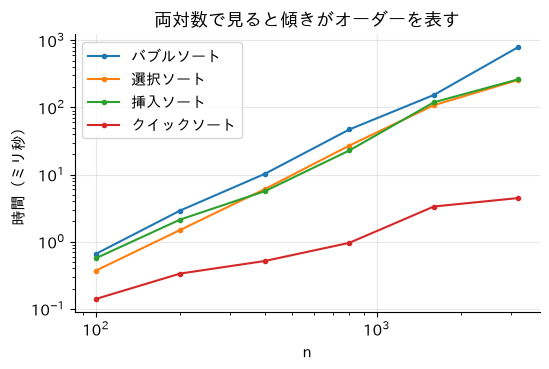

In [6]:
fig, ax = plt.subplots()
for name in sorts:
    ax.loglog(sizes, [t * 1e3 for t in times[name]], marker="o",
              markersize=3, label=name + "ソート")
ax.set_xlabel("n")
ax.set_ylabel("時間（ミリ秒）")
ax.set_title("両対数で見ると傾きがオーダーを表す")
ax.legend()
plt.show()

3 つの単純なソートは傾きがほぼ 2（$O(n^2)$），
クイックソートだけ傾きが 1 に近い（$O(n \log n)$）。

$n$ を 2 倍にすると，$O(n^2)$ は 4 倍，$O(n\log n)$ は 2 倍と少しになる。
表の数字でも確かめてみてほしい。

## 整列済みの入力を与えると

末尾をピボットにとるクイックソートの弱点である。
分割が「$n-1$ 個と 0 個」に偏り続ける。

In [7]:
n = 800
print(f"{'入力':<10}{'時間 (ms)':>12}{'比較回数':>14}")
for label, data in (("でたらめ", random.sample(range(10**6), n)),
                    ("整列済み", list(range(n)))):
    t = timeit(quicksort, data)
    c = Counter()
    quicksort(data[:], c)
    print(f"{label:<10}{t * 1e3:>12.2f}{c.cmp:>14,}")
print()
print(f"参考: n(n-1)/2 = {n * (n - 1) // 2:,}")

入力             時間 (ms)          比較回数
でたらめ              0.86         7,752
整列済み             31.83       319,600

参考: n(n-1)/2 = 319,600


整列済みの入力では，比較回数が $n(n-1)/2$ に張り付いている。
**選択ソートと同じ**である。

### 再帰の深さにも出る

偏った分割では再帰が $n$ 段積まれる。
これは領域計算量 $O(n)$ がそのまま現れたもので，
Python では再帰の上限として目に見える。

In [8]:
import sys

print("再帰の上限:", sys.getrecursionlimit())

for n in (900, 2000):
    try:
        quicksort(list(range(n)), Counter())
        print(f"n = {n:5d}  整列済み → 成功")
    except RecursionError:
        print(f"n = {n:5d}  整列済み → RecursionError")

再帰の上限: 1000
n =   900  整列済み → 成功


n =  2000  整列済み → RecursionError


でたらめな入力なら深さは $O(\log n)$ なので，この上限には当たらない。
**同じ手続きが，入力しだいで止まったり止まらなかったりする。**

## 乱択で直す

ピボットを一様ランダムに選ぶ。
末尾と入れ替えてから `PARTITION` を呼べばよい。

In [9]:
def randomized_partition(a, p, r, c):
    k = random.randrange(p, r + 1)
    a[k], a[r] = a[r], a[k]          # 選んだピボットを末尾へ
    return partition(a, p, r, c)


def randomized_quicksort(a, c, p=0, r=None):
    if r is None:
        r = len(a) - 1
    if p < r:
        q = randomized_partition(a, p, r, c)
        randomized_quicksort(a, c, p, q - 1)
        randomized_quicksort(a, c, q + 1, r)
    return a


import math

random.seed(3)
n = 2000
data = list(range(n))            # 整列済み。末尾ピボットには最悪の入力

c = Counter()
t = timeit(randomized_quicksort, data)
randomized_quicksort(data[:], c)
print(f"乱択クイックソート  時間 {t * 1e3:.2f} ms  比較 {c.cmp:,}")
print(f"参考: n(n-1)/2 = {n * (n - 1) // 2:,}")
print(f"参考: n log2 n = {int(n * math.log2(n)):,} 程度")

乱択クイックソート  時間 3.49 ms  比較 23,473
参考: n(n-1)/2 = 1,999,000
参考: n log2 n = 21,931 程度


整列済みの入力でも落ちない。再帰の上限にも当たらない。

**入力は何ひとつ変えていない。** 変えたのはアルゴリズムの側である。
確率がアルゴリズムの中から来ているので，
「この入力を与えれば遅くなる」という入力が存在しなくなった。

ただし **最悪時計算量は $O(n^2)$ のまま**である。
運が悪ければ毎回端のピボットを引く。確率が小さいだけである。

## 安定性を使う

Python の `sorted` と `list.sort` は安定である。
これを使うと，2 つの基準による並べ替えが 2 回のソートで書ける。

In [10]:
records = [("理工", 2026002), ("文情", 2026003), ("理工", 2026005),
           ("文情", 2026007), ("理工", 2026009)]

r = records[:]
r.sort(key=lambda x: x[1])      # 先に学籍番号（細かいほう）
r.sort(key=lambda x: x[0])      # 次に学部
for x in r:
    print(x)

('文情', 2026003)
('文情', 2026007)
('理工', 2026002)
('理工', 2026005)
('理工', 2026009)


In [11]:
# 2 回目に安定でないソートを使うと、1 回目の順序が壊れる
def selection_sort_by(a, key):
    """安定でないソート（選択ソート）。"""
    n = len(a)
    for i in range(n - 1):
        lo = i
        for j in range(i + 1, n):
            if key(a[j]) < key(a[lo]):
                lo = j
        a[i], a[lo] = a[lo], a[i]
    return a


r = records[:]
r.sort(key=lambda x: x[1])                      # 安定
selection_sort_by(r, key=lambda x: x[0])        # 安定でない
for x in r:
    print(x)

('文情', 2026003)
('文情', 2026007)
('理工', 2026005)
('理工', 2026002)
('理工', 2026009)


学部のまとまりはできているが，**学部の中の学籍番号順が崩れている**。
安定でないソートを 2 回目に使うと，1 回目の仕事が無駄になる。

**細かいほうから先に並べる。そして 2 回目が安定であること。**
この 2 つが揃ってはじめて多段の並べ替えができる。

## 小さい配列では挿入ソートが速い

$O$ 記法では挿入ソートのほうが遅いはずだが，
$n$ が小さいところでは逆転する。境目を探してみる。

In [12]:
random.seed(4)
print(f"{'n':>5}{'挿入 (us)':>12}{'クイック (us)':>14}")
for n in (4, 8, 16, 32, 64, 128):
    data = random.sample(range(10**6), n)
    reps = 2000
    ti = timeit(insertion_sort, data, reps) * 1e6
    tq = timeit(quicksort, data, reps) * 1e6
    mark = "  ← 挿入が速い" if ti < tq else ""
    print(f"{n:>5}{ti:>12.2f}{tq:>14.2f}{mark}")

    n     挿入 (us)     クイック (us)
    4        0.59          1.54  ← 挿入が速い
    8        2.24          4.00  ← 挿入が速い
   16        8.82          6.79
   32       28.37         14.32


   64      104.24         34.27


  128      370.83         92.74


小さいうちは挿入ソートが勝つ。
境目がどこに来るかは実装によって変わるので，数値そのものより**逆転が起きること**を見てほしい。
関数呼び出しやピボットの選択といった **固定費** が，
クイックソートの側にだけかかるためである。

実際の処理系がクイックソートの途中で小さい部分配列を挿入ソートに切り替えるのは，
この境目を利用している。

## Timsort は乱れ具合を利用する

`list.sort` は Timsort で，すでに整列している区間を見つけて使う。

In [13]:
random.seed(5)
n = 1_000_000
base = list(range(n))

cases = {
    "整列済み": base[:],
    "ほぼ整列済み（1000 か所入れ替え）": None,
    "でたらめ": random.sample(range(10**9), n),
    "降順": base[::-1],
}
a = base[:]
for _ in range(1000):
    i, j = random.randrange(n), random.randrange(n)
    a[i], a[j] = a[j], a[i]
cases["ほぼ整列済み（1000 か所入れ替え）"] = a

for label, data in cases.items():
    t0 = time.perf_counter()
    sorted(data)
    print(f"{label:<34}{(time.perf_counter() - t0) * 1e3:8.1f} ms")

整列済み                                  18.3 ms
ほぼ整列済み（1000 か所入れ替え）                   23.7 ms


でたらめ                                 321.8 ms
降順                                    16.8 ms


でたらめな入力より，整列済み・ほぼ整列済み・降順のほうがずっと速い。
降順が速いのは，Timsort が降順の区間を見つけて反転して使うからである。

実データには「部分的に整列している」ものが多いので，この工夫がよく効く。

## まとめ

- バブルソートと選択ソートの**比較回数は入力によらない**。挿入ソートは入力による
- 挿入ソートの比較回数は **転倒数 $+\, (n-1)$** にほぼ等しい
- 両対数の図では **傾きがオーダー**。単純なソートは 2，クイックソートは 1 に近い
- 末尾ピボットのクイックソートは **整列済みの入力で $O(n^2)$**。再帰の深さも $n$ になる
- **乱択**にすると同じ入力でも落ちない。変えたのは入力ではなくアルゴリズムの側
- 2 段の並べ替えは「細かいほうから先に」「2 回目が安定」の両方が要る
- 小さい $n$ では挿入ソートが速い。$O$ 記法で消えた定数倍が効くため